# Keyword and Entity Extraction using IBM WatsonX.ai

This notebook demonstrates how to extract keywords and entities from the IBM test data (parquet format) using IBM WatsonX.ai foundation models, followed by comprehensive statistical analysis.

## Table of Contents
1. [Setup and Installation](#setup)
2. [Load Dataset from Parquet](#load-data)
3. [Initialize WatsonX.ai Client](#init-watsonx)
4. [Keyword Extraction](#keyword-extraction)
5. [Entity Extraction](#entity-extraction)
6. [Batch Processing](#batch-processing)
7. [Save Results](#save-results)
8. [Statistical Analysis](#statistical-analysis)

## 1. Setup and Installation <a name="setup"></a>

First, install the required packages.

### Import Required Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import json
import re
from typing import List, Dict, Optional
from collections import Counter
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import seaborn as sns

# IBM WatsonX.ai imports
from ibm_watsonx_ai.credentials import Credentials
from ibm_watsonx_ai import APIClient
from ibm_watsonx_ai.foundation_models import ModelInference

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


### Configure Credentials

Set up your IBM Cloud credentials. Refer to `IBM_CREDENTIALS_SETUP.md` for detailed instructions.

In [2]:
# Load environment variables
load_dotenv()

WATSONX_API_KEY = os.getenv('WATSONX_API_KEY', 'your-api-key-here')
WATSONX_PROJECT_ID = os.getenv('WATSONX_PROJECT_ID', 'your-project-id-here')
WATSONX_URL = os.getenv('WATSONX_URL', 'https://us-south.ml.cloud.ibm.com')

if WATSONX_API_KEY == 'your-api-key-here':
    print("⚠️  Warning: Please set your WatsonX.ai credentials")
else:
    print("✓ Credentials loaded successfully")

✓ Credentials loaded successfully


## 2. Load Dataset <a name="load-data"></a>

In [ ]:
### Replace with your data file
csv_path = "/Users/abhilashamangal/Documents/2026/Github/ShareThis-Predictive-Multilabel-Classification/data/with_label.csv"

df = pd.read_csv(csv_path)
print(f"✓ Dataset loaded: {df.shape}")
print(f"  Columns: {list(df.columns)}")
display(df.head(3))
df.info()

✓ Dataset loaded: (1153, 3)
  Columns: ['url', 'text', 'label']


,url,text,label
0,https://abcnews.go.com/International/photos/is...,Israel-Gaza-Lebanon-Syria conflict: Slideshow ...,['/arts_&_entertainment/online_media/online_im...
1,https://acapt.org/educationevents/advancing-ac...,Advancing Accessibility & Disability Equity Su...,['/business_&_industrial/business_services/cor...
2,https://adcable.com/products/rf-communication....,RF Wire & Cable Manufacturer | Advanced Digita...,['/computers_&_electronics/electronics_&_elect...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1153 entries, 0 to 1152
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   url     1153 non-null   object
 1   text    1153 non-null   object
 2   label   1153 non-null   object
dtypes: object(3)
memory usage: 27.2+ KB


In [4]:
# Prepare sample
SAMPLE_SIZE = 100
df_sample = df.head(SAMPLE_SIZE).copy()
print(f"✓ Prepared {len(df_sample)} samples")

✓ Prepared 100 samples


## 3. Initialize WatsonX.ai Client <a name="init-watsonx"></a>

In [5]:
credentials = Credentials(url=WATSONX_URL, api_key=WATSONX_API_KEY)
MODEL_ID = "mistralai/mistral-small-3-1-24b-instruct-2503"
parameters = {
    "decoding_method": "greedy",
    "temperature": 0.1,
    "max_new_tokens": 2000,
    "min_new_tokens": 10,
    "repetition_penalty": 1.0
}

model = ModelInference(
    model_id=MODEL_ID,
    params=parameters,
    credentials=credentials,
    project_id=WATSONX_PROJECT_ID
)
print(f"✓ Model initialized: {MODEL_ID}")

✓ Model initialized: mistralai/mistral-small-3-1-24b-instruct-2503


In [6]:
from web_scraper import WebScraper
scraper = WebScraper()

## 4. Keyword Extraction <a name="keyword-extraction"></a>

In [7]:
import json
from typing import Dict, Any
def extract_keywords(text: str, url: str = "", max_keywords: int = 10) -> Dict[str, Any]:
   
    prompt = f"""[INST]

    You are an expert NLP information extraction system.

    TASK:
    Analyze the given text and extract the most important information into three distinct categories:

    1. keywords → Important single-word terms only
    2. phrases → Important multi-word key phrases only
    3. concepts → High-level themes, categories, or core ideas discussed in the text

    PRE-REQUIRED THEME UNDERSTANDING:
    Before extraction, first understand:
    - the main subject of the text
    - the domain it belongs to
    - the primary discussion theme
    - the important technical context

    Then perform extraction based on semantic importance, not just word frequency.

    STRICT EXTRACTION RULES:
    - Extract up to {max_keywords} total items across all categories combined
    - keywords must contain only single meaningful words
    - phrases must contain only multi-word expressions
    - concepts must represent broader ideas, categories, or major themes
    - Do NOT duplicate the same term across categories
    - Do NOT repeat the same idea in slightly different forms
    - Do NOT include sub-phrases if a stronger full phrase exists

    Example:
    Prefer "Natural Language Processing" over "Language Processing"

    - Prefer complete and meaningful expressions
    - Preserve exact technical names where relevant
    - Exclude generic words, filler words, weak terms, and low-value tokens
    - Prioritize domain-specific and contextually important information
    - Keep output concise, clean, and highly relevant

    STRICT OUTPUT RULES:
    - Return ONLY valid JSON
    - Do NOT include markdown
    - Do NOT include explanations
    - Do NOT include notes
    - Do NOT include additional text before or after JSON
    - If unsure, return empty arrays instead of explanations

    RETURN EXACTLY IN THIS JSON STRUCTURE:

    {{
      "theme": "main topic of the text",
      "keywords": [
        "keyword1",
        "keyword2"
      ],
      "phrases": [
        "key phrase 1",
        "key phrase 2"
      ],
      "concepts": [
        "core concept 1",
        "core concept 2"
      ]
    }}

    TEXT:
    {text}

    [/INST]"""

    try:
        print(f"Prompt:\n{prompt}")

        result = model.generate_text(
            prompt=prompt,
            guardrails=False
        )

        result = result.strip()

        print("Raw Model Output:")
        print(result)

        # Parse only valid JSON object
        if result.startswith("{") and result.endswith("}"):
            parsed_result = json.loads(result)

            # Safety fallback for missing keys
            return {
                "theme": parsed_result.get("theme", ""),
                "keywords": parsed_result.get("keywords", []),
                "phrases": parsed_result.get("phrases", []),
                "concepts": parsed_result.get("concepts", [])
            }

        print("Invalid JSON response received")
        return {
            "theme": "",
            "keywords": [],
            "phrases": [],
            "concepts": []
        }

    except Exception as e:
        print(f"Keyword extraction error: {str(e)}")

        return {
            "theme": "",
            "keywords": [],
            "phrases": [],
            "concepts": []
        }


print("✓ Keyword extraction function defined")

✓ Keyword extraction function defined


## 5. Entity Extraction <a name="entity-extraction"></a>

In [8]:
import json
from typing import Dict, List

def extract_entities(text: str, url: str = "") -> Dict[str, List[str]]:
    print("Entity extraction started -----")

    prompt = f"""[INST]

You are an expert Named Entity Recognition (NER) and entity extraction system.

TASK:
Analyze the given text and extract all important named entities, then categorize them into the appropriate entity types.

ENTITY CATEGORIES:
- PERSON → Individual people, authors, researchers, founders, public figures
- ORGANIZATION → Companies, institutions, universities, agencies, teams, brands
- LOCATION → Countries, cities, states, regions, landmarks, places
- DATE → Specific dates, years, months, time references
- EVENT → Conferences, wars, launches, festivals, historical events, major occurrences
- PRODUCT → Software, tools, applications, devices, frameworks, commercial products
- OTHER → Important named entities that do not clearly fit the above categories

PRE-ANALYSIS:
Before extraction, first understand:
- the main subject of the text
- the domain and context
- whether the term is truly a named entity or just a generic noun

Then perform entity extraction based on contextual meaning, not only capitalization.

STRICT EXTRACTION RULES:
- Extract only meaningful named entities
- Do NOT include generic words or common nouns
- Do NOT include duplicate entities
- Do NOT repeat the same entity in multiple categories
- Preserve exact entity names as written when possible
- Prefer full entity names over partial names

Example:
Prefer "Stanford University" over "Stanford"

- Ignore weak references unless they are contextually important
- Keep output clean, precise, and domain-relevant

STRICT OUTPUT RULES:
- Return ONLY valid JSON
- Do NOT include markdown
- Do NOT include explanations
- Do NOT include notes
- Do NOT include additional text before or after JSON
- If no entities exist for a category, return an empty array
- If unsure, return empty arrays instead of explanations

RETURN EXACTLY IN THIS JSON STRUCTURE:

{{
  "PERSON": [],
  "ORGANIZATION": [],
  "LOCATION": [],
  "DATE": [],
  "EVENT": [],
  "PRODUCT": [],
  "OTHER": []
}}

TEXT:
{text}

[/INST]"""

    try:
        result = model.generate_text(
            prompt=prompt,
            guardrails=False
        )

        result = result.strip()

        # Extract valid JSON block safely
        start_idx = result.find("{")
        end_idx = result.rfind("}")

        if start_idx != -1 and end_idx != -1:
            json_text = result[start_idx:end_idx + 1]

            parsed_result = json.loads(json_text)

            # Ensure all required keys exist
            return {
                "PERSON": parsed_result.get("PERSON", []),
                "ORGANIZATION": parsed_result.get("ORGANIZATION", []),
                "LOCATION": parsed_result.get("LOCATION", []),
                "DATE": parsed_result.get("DATE", []),
                "EVENT": parsed_result.get("EVENT", []),
                "PRODUCT": parsed_result.get("PRODUCT", []),
                "OTHER": parsed_result.get("OTHER", [])
            }

        print("Invalid JSON response received")

        return {
            "PERSON": [],
            "ORGANIZATION": [],
            "LOCATION": [],
            "DATE": [],
            "EVENT": [],
            "PRODUCT": [],
            "OTHER": []
        }

    except Exception as e:
        print(f"Entity extraction error: {str(e)}")

        return {
            "PERSON": [],
            "ORGANIZATION": [],
            "LOCATION": [],
            "DATE": [],
            "EVENT": [],
            "PRODUCT": [],
            "OTHER": []
        }


print("✓ Entity extraction function defined")

✓ Entity extraction function defined


## 6. Batch Processing <a name="batch-processing"></a>

In [9]:
import pandas as pd
from typing import Dict, Any

def process_batch(df: pd.DataFrame, max_keywords: int = 50) -> pd.DataFrame:
    """
    Process dataframe and add:
    - theme
    - keywords
    - phrases
    - concepts
    - PERSON
    - ORGANIZATION
    - LOCATION
    - DATE
    - EVENT
    - PRODUCT
    - OTHER

    Rule:
    If scraper does NOT return text successfully,
    store error message in `text` column and DO NOT run
    keyword/entity extraction for that row.
    """

    results = []

    # Detect columns
    text_col = "text" if "text" in df.columns else df.columns[0]
    url_col = "url" if "url" in df.columns else None

    print("\nStarting batch processing...")
    print("=" * 70)

    for idx, row in df.iterrows():
        url = row[url_col] if url_col else ""

        print(f"\nProcessing {idx + 1}/{len(df)}...")
        print(f"URL: {url}")

        try:
            # -----------------------------
            # Step 1: Scrape URL
            # -----------------------------
            result = scraper.scrape(url)

            # If scraper failed OR no cleaned_text found
            if (
                result.get("status") != "success"
                or not result.get("cleaned_text")
                or not str(result.get("cleaned_text")).strip()
            ):
                error_msg = result.get("error", "Scraper failed: No text extracted")

                print(f"❌ Scraper Error: {error_msg}")

                # IMPORTANT:
                # Save error in text column
                # DO NOT run extract_keywords / extract_entities
                results.append({
                    "text": f"ERROR: {error_msg}",
                    "metadata": result.get("metadata", {}),
                    "theme": "",
                    "keywords": [],
                    "phrases": [],
                    "concepts": [],

                    "PERSON": [],
                    "ORGANIZATION": [],
                    "LOCATION": [],
                    "DATE": [],
                    "EVENT": [],
                    "PRODUCT": [],
                    "OTHER": []
                })

                # Skip remaining processing for this row
                continue

            # -----------------------------
            # Step 2: Use scraped text
            # -----------------------------
            text = result["raw_text"]

            print(f"Title: {result.get('metadata', {}).get('title', '')}")
            print(f"Text Preview: {text[:200]}...")

            # -----------------------------
            # Step 3: Extract keywords
            # -----------------------------
            keyword_data = extract_keywords(
                text=text,
                url=url,
                max_keywords=max_keywords
            )

            print("Keyword Extraction Result:")
            print(keyword_data)

            # -----------------------------
            # Step 4: Extract entities
            # -----------------------------
            entity_data = extract_entities(
                text=text,
                url=url
            )

            total_entities = sum(
                len(v) for v in entity_data.values()
            )

            print(
                f"✓ Theme extracted | "
                f"Keywords: {len(keyword_data.get('keywords', []))} | "
                f"Phrases: {len(keyword_data.get('phrases', []))} | "
                f"Concepts: {len(keyword_data.get('concepts', []))} | "
                f"Entities: {total_entities}"
            )

            results.append({
                "text": text,
                "metadata": result.get("metadata", {}),
                "theme": keyword_data.get("theme", ""),
                "keywords": keyword_data.get("keywords", []),
                "phrases": keyword_data.get("phrases", []),
                "concepts": keyword_data.get("concepts", []),

                "PERSON": entity_data.get("PERSON", []),
                "ORGANIZATION": entity_data.get("ORGANIZATION", []),
                "LOCATION": entity_data.get("LOCATION", []),
                "DATE": entity_data.get("DATE", []),
                "EVENT": entity_data.get("EVENT", []),
                "PRODUCT": entity_data.get("PRODUCT", []),
                "OTHER": entity_data.get("OTHER", [])
            })

        except Exception as e:
            error_msg = f"Processing error: {str(e)}"
            print(f"❌ Error processing row {idx}: {error_msg}")

            results.append({
                "text": f"ERROR: {error_msg}",
                "metadata": {},
                "theme": "",
                "keywords": [],
                "phrases": [],
                "concepts": [],

                "PERSON": [],
                "ORGANIZATION": [],
                "LOCATION": [],
                "DATE": [],
                "EVENT": [],
                "PRODUCT": [],
                "OTHER": []
            })

    # ---------------------------------
    # Add extracted values back to df
    # ---------------------------------
    df["scrape_text"] = [r["text"] for r in results]
    df["metadata"] = [r["metadata"] for r in results]
    df["theme"] = [r["theme"] for r in results]
    df["keywords"] = [r["keywords"] for r in results]
    df["phrases"] = [r["phrases"] for r in results]
    df["concepts"] = [r["concepts"] for r in results]

    df["PERSON"] = [r["PERSON"] for r in results]
    df["ORGANIZATION"] = [r["ORGANIZATION"] for r in results]
    df["LOCATION"] = [r["LOCATION"] for r in results]
    df["DATE"] = [r["DATE"] for r in results]
    df["EVENT"] = [r["EVENT"] for r in results]
    df["PRODUCT"] = [r["PRODUCT"] for r in results]
    df["OTHER"] = [r["OTHER"] for r in results]

    print("\n✓ Batch processing completed successfully")

    return df


print("✓ Batch processing function defined")

✓ Batch processing function defined


In [ ]:
print(f"Starting batch processing...\n" + "="*70)
df_results = process_batch(df_sample, max_keywords=10)
print("\n" + "="*70 + "\n✓ Complete!")

In [11]:
df_results['scrape_text']

0     Middle East conflict: Slideshow 1 of 489 A man...
1                            ERROR: Failed to fetch URL
2                      h7DóP„s_6­Þ¦jÿ>]À¾¢\t®\xSšp!MµA`
3                            ERROR: Failed to fetch URL
4                              ÀQ”´ÚbDjR€FÊÂùûGèð9ï«_šÿ
                            ...                        
95    ERROR: Parsing error: 'NoneType' object has no...
96    ERROR: Parsing error: 'NoneType' object has no...
97    In the Palace of Science (Part 1 of 2) By Chri...
98    In the Palace of Science (Part 1 of 2) By Chri...
99    ERROR: Parsing error: 'NoneType' object has no...
Name: scrape_text, Length: 100, dtype: object

In [12]:
# View sample results
for idx in range(min(3, len(df_results))):
    row = df_results.iloc[idx]
    print(f"\n{'='*70}\nSample {idx+1}\n{'='*70}")
    print(f"Keywords ({len(row['keywords'])}): {row['keywords']}")
    print(f"Entities: {row['OTHER']}")


Sample 1
Keywords (4): ['conflict', 'Israel', 'Gaza', 'Hamas']
Entities: ['Getty Images']

Sample 2
Keywords (0): []
Entities: []

Sample 3
Keywords (0): []
Entities: []


## 7. Save Results <a name="save-results"></a>

In [13]:
output_json = "../data/extraction_results_csv_100.json"
df_results.to_json(output_json, orient='records', indent=2)

print(f"✓ Results saved:\n  JSON: {output_json}")

✓ Results saved:
  JSON: ../data/extraction_results_csv_100.json


## 8. Statistical Analysis <a name="statistical-analysis"></a>

Comprehensive analysis of extracted keywords and entities.

In [14]:
def count_error_rows(df: pd.DataFrame, text_column: str = "text") -> int:
    """
    Count how many rows contain scraper/processing errors.

    Logic:
    - Checks if text column starts with 'ERROR:'

    Example:
        error_count = count_error_rows(df)
        print(error_count)
    """

    if text_column not in df.columns:
        raise ValueError(f"Column '{text_column}' not found in dataframe")

    error_count = (
        df[text_column]
        .fillna("")
        .astype(str)
        .str.startswith("ERROR:")
        .sum()
    )

    print(f"Total rows with errors: {error_count}")

    return error_count


# Example usage
error_count = count_error_rows(df_results,'scrape_text')

Total rows with errors: 55


### 8.1 Basic Statistics

In [15]:
# Check if dataframe has separate columns or combined columns
has_separate_cols = 'keywords' in df_results.columns and 'phrases' in df_results.columns
entity_cols = ['PERSON', 'ORGANIZATION', 'LOCATION', 'DATE', 'EVENT', 'PRODUCT', 'OTHER']

if has_separate_cols:
    # Count from separate columns
    total_keywords = sum(len(kw) if isinstance(kw, list) else 0 for kw in df_results['keywords'])
    total_phrases = sum(len(p) if isinstance(p, list) else 0 for p in df_results['phrases'])
    total_concepts = sum(len(c) if isinstance(c, list) else 0 for c in df_results['concepts'])
    total_all = total_keywords + total_phrases + total_concepts
    
    # Count entities from separate columns
    total_entities = sum(sum(len(df_results[col].iloc[i]) if isinstance(df_results[col].iloc[i], list) else 0 
                             for col in entity_cols if col in df_results.columns) 
                        for i in range(len(df_results)))
else:
    # Fallback to dictionary format
    def count_keyword_items(kw_dict):
        if isinstance(kw_dict, dict):
            total = 0
            if 'keywords' in kw_dict:
                total += len(kw_dict['keywords'])
            if 'phrases' in kw_dict:
                total += len(kw_dict['phrases'])
            if 'concepts' in kw_dict:
                total += len(kw_dict['concepts'])
            return total
        return len(kw_dict) if isinstance(kw_dict, list) else 0
    
    total_all = sum(count_keyword_items(kw) for kw in df_results['keywords'])
    total_entities = sum(sum(len(v) for v in ent.values()) if isinstance(ent, dict) else 0 for ent in df_results['entities'])

avg_all = total_all / len(df_results)
avg_entities = total_entities / len(df_results)

print("="*80)
print("EXTRACTION SUMMARY")
print("="*80)
print(f"\nSamples processed: {len(df_results)}")

if has_separate_cols:
    print(f"\nKeywords: {total_keywords}")
    print(f"Phrases: {total_phrases}")
    print(f"Concepts: {total_concepts}")
    print(f"Total (Keywords + Phrases + Concepts): {total_all}")
    print(f"Average per sample: {avg_all:.2f}")
else:
    print(f"\nTotal (Keywords + Phrases + Concepts): {total_all}")
    print(f"Average per sample: {avg_all:.2f}")

print(f"\nEntities:")
print(f"  Total: {total_entities}")
print(f"  Average: {avg_entities:.2f}")

if has_separate_cols:
    print(f"\nEntity breakdown:")
    for col in entity_cols:
        if col in df_results.columns:
            count = sum(len(df_results[col].iloc[i]) if isinstance(df_results[col].iloc[i], list) else 0 
                       for i in range(len(df_results)))
            print(f"  {col}: {count}")

print("\n" + "="*80)

EXTRACTION SUMMARY

Samples processed: 100

Keywords: 51
Phrases: 35
Concepts: 24
Total (Keywords + Phrases + Concepts): 110
Average per sample: 1.10

Entities:
  Total: 436
  Average: 4.36

Entity breakdown:
  PERSON: 27
  ORGANIZATION: 46
  LOCATION: 114
  DATE: 39
  EVENT: 46
  PRODUCT: 19
  OTHER: 145



### 8.2 Keyword Distribution

KEYWORD DISTRIBUTION (including phrases and concepts)
Mean: 1.10
Median: 0.00
Std Dev: 3.04


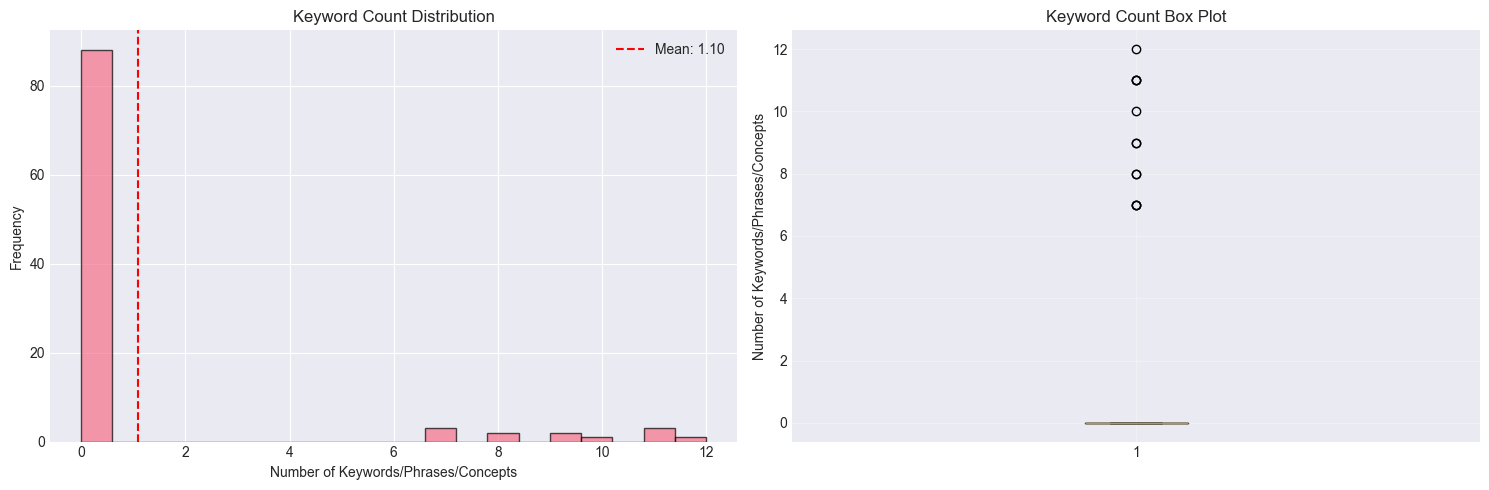

In [16]:
if has_separate_cols:
    keyword_counts = [len(df_results['keywords'].iloc[i]) + len(df_results['phrases'].iloc[i]) + len(df_results['concepts'].iloc[i]) 
                     if isinstance(df_results['keywords'].iloc[i], list) else 0 
                     for i in range(len(df_results))]
else:
    keyword_counts = [count_keyword_items(kw) for kw in df_results['keywords']]

print("KEYWORD DISTRIBUTION (including phrases and concepts)")
print(f"Mean: {np.mean(keyword_counts):.2f}")
print(f"Median: {np.median(keyword_counts):.2f}")
print(f"Std Dev: {np.std(keyword_counts):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(keyword_counts, bins=20, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Number of Keywords/Phrases/Concepts')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Keyword Count Distribution')
axes[0].axvline(np.mean(keyword_counts), color='red', linestyle='--', label=f'Mean: {np.mean(keyword_counts):.2f}')
axes[0].legend()

axes[1].boxplot(keyword_counts)
axes[1].set_ylabel('Number of Keywords/Phrases/Concepts')
axes[1].set_title('Keyword Count Box Plot')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8.3 Most Common Keywords

TOP 20 MOST COMMON KEYWORDS/PHRASES/CONCEPTS

Total unique items: 80

   1. verification                             -   3 occurrences
   2. connection                               -   3 occurrences
   3. redirecting                              -   3 occurrences
   4. automated access                         -   3 occurrences
   5. verification successful                  -   3 occurrences
   6. security protocols                       -   3 occurrences
   7. browser verification                     -   3 occurrences
   8. images                                   -   2 occurrences
   9. library                                  -   2 occurrences
  10. project                                  -   2 occurrences
  11. colors                                   -   2 occurrences
  12. royalty-free stock photos                -   2 occurrences
  13. professor                                -   2 occurrences
  14. science                                  -   2 occurrences
  15. discovery     

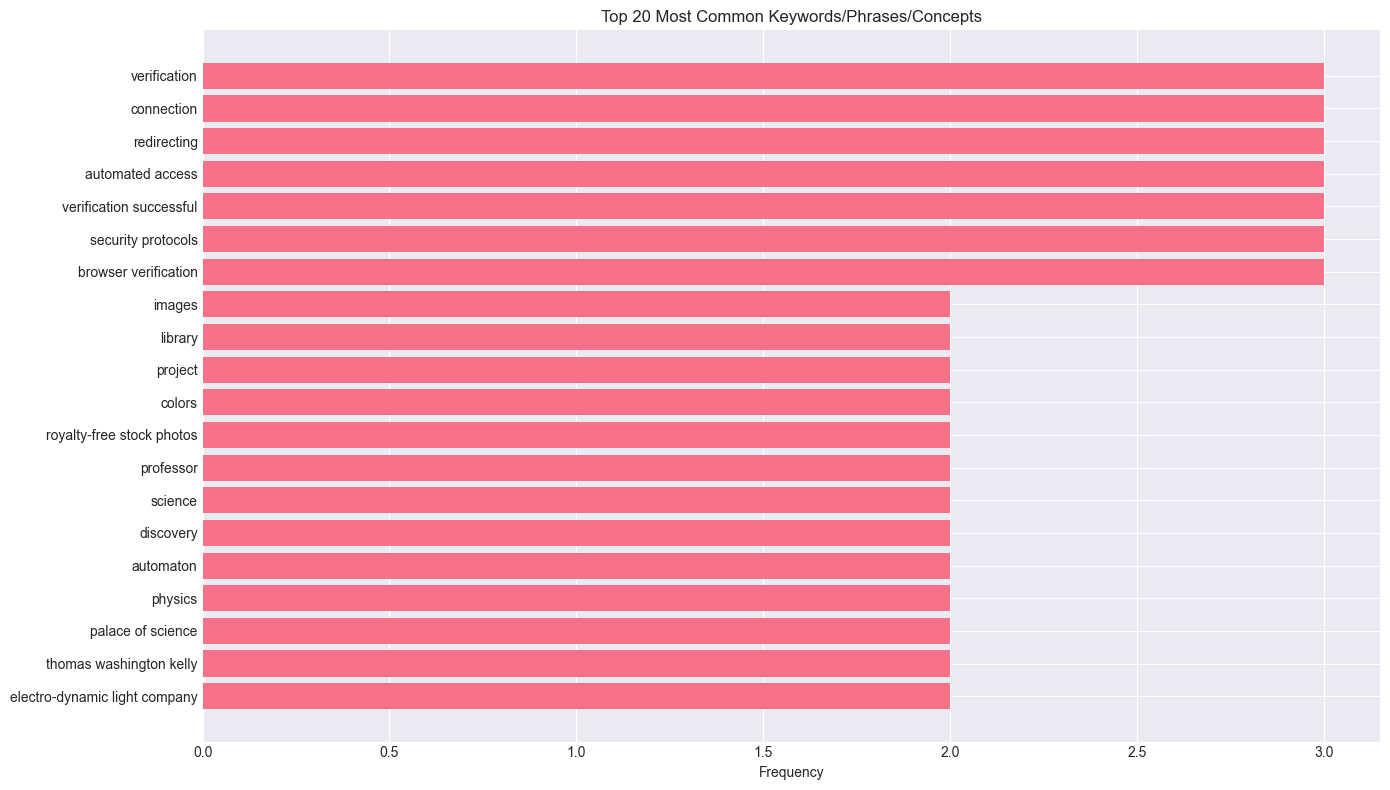

In [17]:
# Extract all keywords, phrases, and concepts
all_keywords = []

if has_separate_cols:
    # Extract from separate columns
    for i in range(len(df_results)):
        if isinstance(df_results['keywords'].iloc[i], list):
            all_keywords.extend([kw.lower() for kw in df_results['keywords'].iloc[i]])
        if isinstance(df_results['phrases'].iloc[i], list):
            all_keywords.extend([p.lower() for p in df_results['phrases'].iloc[i]])
        if isinstance(df_results['concepts'].iloc[i], list):
            all_keywords.extend([c.lower() for c in df_results['concepts'].iloc[i]])
else:
    # Extract from dictionary format
    for kw_dict in df_results['keywords']:
        if isinstance(kw_dict, dict):
            if 'keywords' in kw_dict:
                all_keywords.extend([kw.lower() for kw in kw_dict['keywords']])
            if 'phrases' in kw_dict:
                all_keywords.extend([kw.lower() for kw in kw_dict['phrases']])
            if 'concepts' in kw_dict:
                all_keywords.extend([kw.lower() for kw in kw_dict['concepts']])
        elif isinstance(kw_dict, list):
            all_keywords.extend([kw.lower() for kw in kw_dict])

keyword_counter = Counter(all_keywords)
top_keywords = keyword_counter.most_common(20)

print("="*80)
print("TOP 20 MOST COMMON KEYWORDS/PHRASES/CONCEPTS")
print("="*80)
print(f"\nTotal unique items: {len(keyword_counter)}\n")
for i, (kw, count) in enumerate(top_keywords, 1):
    print(f"  {i:2d}. {kw:40s} - {count:3d} occurrences")

if top_keywords:
    keywords, counts = zip(*top_keywords)
    plt.figure(figsize=(14, 8))
    plt.barh(range(len(keywords)), counts)
    plt.yticks(range(len(keywords)), keywords)
    plt.xlabel('Frequency')
    plt.title('Top 20 Most Common Keywords/Phrases/Concepts')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

### 8.4 Entity Type Distribution

ENTITY TYPE DISTRIBUTION

Total entity types: 7

  OTHER               :  145 entities
  LOCATION            :  114 entities
  ORGANIZATION        :   46 entities
  EVENT               :   46 entities
  DATE                :   39 entities
  PERSON              :   27 entities
  PRODUCT             :   19 entities


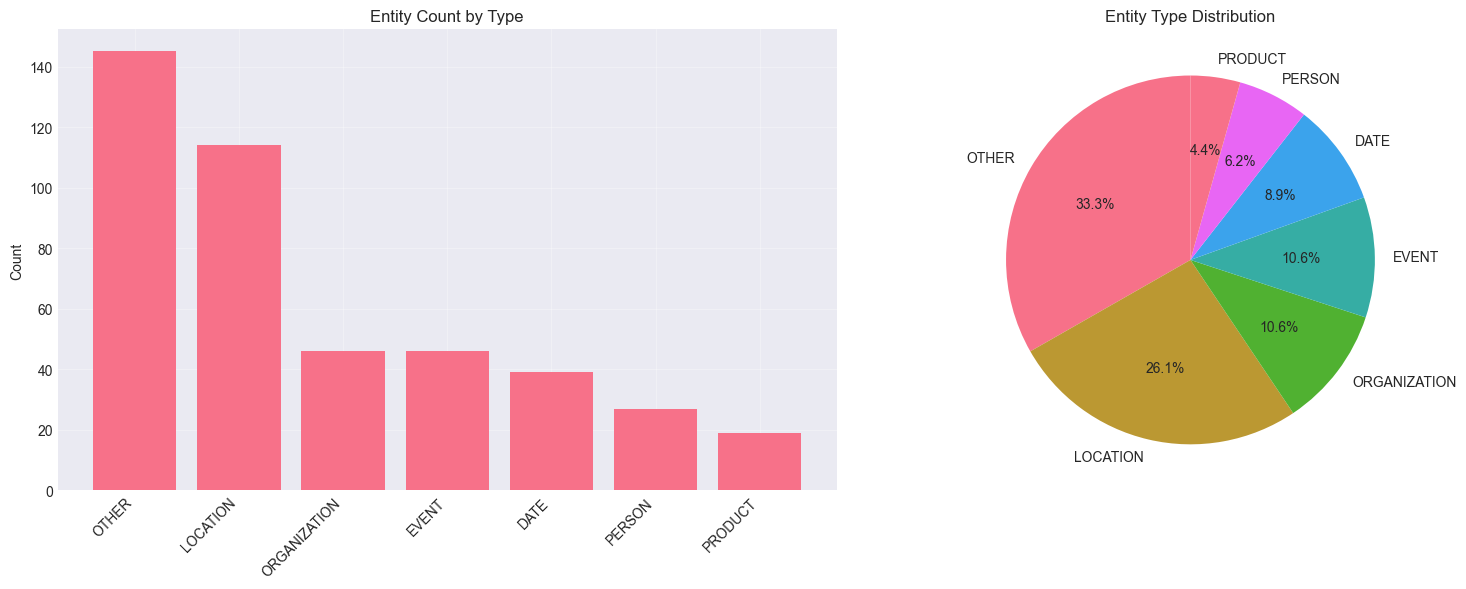

In [18]:
entity_type_counts = Counter()

if has_separate_cols:
    # Count from separate entity columns
    for col in entity_cols:
        if col in df_results.columns:
            count = sum(len(df_results[col].iloc[i]) if isinstance(df_results[col].iloc[i], list) else 0 
                       for i in range(len(df_results)))
            if count > 0:
                entity_type_counts[col] = count
else:
    # Count from entities dictionary
    for entities_dict in df_results['entities']:
        if isinstance(entities_dict, dict):
            for entity_type, entity_list in entities_dict.items():
                entity_type_counts[entity_type] += len(entity_list)

print("="*80)
print("ENTITY TYPE DISTRIBUTION")
print("="*80)
print(f"\nTotal entity types: {len(entity_type_counts)}\n")
for entity_type, count in entity_type_counts.most_common():
    print(f"  {entity_type:20s}: {count:4d} entities")

if entity_type_counts:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    types, counts = zip(*entity_type_counts.most_common())
    
    axes[0].bar(range(len(types)), counts)
    axes[0].set_xticks(range(len(types)))
    axes[0].set_xticklabels(types, rotation=45, ha='right')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Entity Count by Type')
    axes[0].grid(True, alpha=0.3)
    
    axes[1].pie(counts, labels=types, autopct='%1.1f%%', startangle=90)
    axes[1].set_title('Entity Type Distribution')
    
    plt.tight_layout()
    plt.show()